# DataTalksClub ML Zoomcamp 2026 Homework 2

## Regression

## Data Loading and Column Filtering

Load the car fuel efficiency dataset and retain only the five columns required for this homework.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv'
columns = [
    'engine_displacement',
    'horsepower',
    'vehicle_weight',
    'model_year',
    'fuel_efficiency_mpg',
]
target_column = 'fuel_efficiency_mpg'
df = pd.read_csv(url, usecols=columns)

print('Loaded records:', len(df))
print('Selected columns:', list(df.columns))
df.head()

Loaded records: 10000
Selected columns: ['model_year', 'engine_displacement', 'horsepower', 'vehicle_weight', 'fuel_efficiency_mpg']


,model_year,engine_displacement,horsepower,vehicle_weight,fuel_efficiency_mpg
0,2006,2180,243.0,3870,31.9
1,2008,2390,272.0,4210,31.3
2,1996,2320,267.0,4240,27.5
3,1989,2130,258.0,4490,28.5
4,1994,2580,304.0,4510,31.0


## Exploratory Data Analysis

Inspect the target distribution and its skewness to assess whether it has a long tail.

Fuel efficiency summary:
count    10000.000000
mean        29.997700
std          2.930245
min         19.800000
25%         28.000000
50%         30.000000
75%         31.900000
max         41.200000
Name: fuel_efficiency_mpg, dtype: float64
Target skewness: 0.081
Long tail detected: False


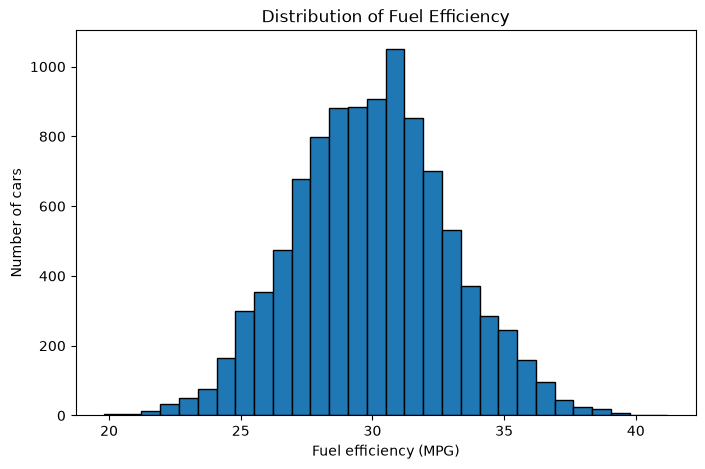

In [2]:
target = df[target_column]
target_skewness = target.skew()
long_tail = abs(target_skewness) > 1

print('Fuel efficiency summary:')
print(target.describe())
print('Target skewness:', round(target_skewness, 3))
print('Long tail detected:', long_tail)

plt.figure(figsize=(8, 5))
plt.hist(target, bins=30, edgecolor='black')
plt.title('Distribution of Fuel Efficiency')
plt.xlabel('Fuel efficiency (MPG)')
plt.ylabel('Number of cars')
plt.show()

## Q1. Missing Values

Identify missing values in each selected column.

In [3]:
missing_counts = df.isna().sum()
missing_columns = missing_counts[missing_counts > 0]

print('Q1 Answer:')
print(missing_columns)

Q1 Answer:
horsepower    877
dtype: int64


## Q2. Median Horsepower

Compute the 50th percentile of horsepower.

In [4]:
horsepower_median = df['horsepower'].median()

print('Q2 Answer:', horsepower_median)

Q2 Answer: 254.0


## Helper Functions

Define linear regression with and without regularization, along with the root mean squared error metric.

In [5]:
def train_linear_regression(X, y):
    X_with_bias = np.column_stack([np.ones(X.shape[0]), X])
    XTX = X_with_bias.T @ X_with_bias
    weights = np.linalg.inv(XTX) @ X_with_bias.T @ y
    return weights


def train_linear_regression_reg(X, y, r):
    X_with_bias = np.column_stack([np.ones(X.shape[0]), X])
    XTX = X_with_bias.T @ X_with_bias
    XTX_regularized = XTX + r * np.eye(XTX.shape[0])
    weights = np.linalg.inv(XTX_regularized) @ X_with_bias.T @ y
    return weights


def rmse(y, y_pred):
    return np.sqrt(np.mean((y - y_pred) ** 2))


def predict(X, weights):
    X_with_bias = np.column_stack([np.ones(X.shape[0]), X])
    return X_with_bias @ weights

## Dataset Split

Split the data into 60% training, 20% validation, and 20% test sets using a shuffled index.

In [6]:
def split_data(data, seed):
    np.random.seed(seed)
    indices = np.arange(len(data))
    np.random.shuffle(indices)

    n_train = int(len(data) * 0.6)
    n_validation = int(len(data) * 0.2)

    train_indices = indices[:n_train]
    validation_indices = indices[n_train:n_train + n_validation]
    test_indices = indices[n_train + n_validation:]

    return (
        data.iloc[train_indices].copy(),
        data.iloc[validation_indices].copy(),
        data.iloc[test_indices].copy(),
    )

## Q3. Imputation Strategy Comparison

Using seed 42, compare validation RMSE when missing feature values are filled with zero versus the training mean.

In [7]:
train_df, validation_df, test_df = split_data(df, seed=42)
feature_columns = [column for column in columns if column != target_column]

def evaluate_imputation(fill_value):
    X_train = train_df[feature_columns].fillna(fill_value).to_numpy()
    X_validation = validation_df[feature_columns].fillna(fill_value).to_numpy()
    y_train = train_df[target_column].to_numpy()
    y_validation = validation_df[target_column].to_numpy()

    weights = train_linear_regression(X_train, y_train)
    validation_predictions = predict(X_validation, weights)
    return rmse(y_validation, validation_predictions)

zero_rmse = evaluate_imputation(0)
training_mean = train_df[feature_columns].mean()
X_train_mean = train_df[feature_columns].fillna(training_mean).to_numpy()
X_validation_mean = validation_df[feature_columns].fillna(training_mean).to_numpy()
y_train = train_df[target_column].to_numpy()
y_validation = validation_df[target_column].to_numpy()
weights_mean = train_linear_regression(X_train_mean, y_train)
mean_predictions = predict(X_validation_mean, weights_mean)
mean_rmse = rmse(y_validation, mean_predictions)

print('Q3 Answer:')
print('Validation RMSE with zero imputation:', round(zero_rmse, 3))
print('Validation RMSE with training-mean imputation:', round(mean_rmse, 3))

Q3 Answer:
Validation RMSE with zero imputation: 2.205
Validation RMSE with training-mean imputation: 2.202


## Q4. Regularization Tuning

Using seed 42 and zero imputation, evaluate the requested regularization values and select the smallest value with the best validation RMSE.

In [8]:
X_train = train_df[feature_columns].fillna(0).to_numpy()
X_validation = validation_df[feature_columns].fillna(0).to_numpy()
y_train = train_df[target_column].to_numpy()
y_validation = validation_df[target_column].to_numpy()
regularization_values = [0, 0.01, 0.1, 1, 5, 10, 100]
regularization_scores = {}

for r in regularization_values:
    weights = train_linear_regression_reg(X_train, y_train, r)
    predictions = predict(X_validation, weights)
    regularization_scores[r] = rmse(y_validation, predictions)

best_r = min(regularization_values, key=lambda value: (regularization_scores[value], value))

print('Q4 Answer:')
for r in regularization_values:
    print(f'r={r}: validation RMSE={round(regularization_scores[r], 4)}')
print('Best r:', best_r)

Q4 Answer:
r=0: validation RMSE=2.2053
r=0.01: validation RMSE=2.2058
r=0.1: validation RMSE=2.2241
r=1: validation RMSE=2.3492
r=5: validation RMSE=2.4094
r=10: validation RMSE=2.4195
r=100: validation RMSE=2.4292
Best r: 0


## Q5. Seed Sensitivity

Repeat the split and validation evaluation for seeds 0 through 9 using zero imputation and no regularization.

In [9]:
scores = []

for seed in range(10):
    seed_train_df, seed_validation_df, _ = split_data(df, seed=seed)
    X_seed_train = seed_train_df[feature_columns].fillna(0).to_numpy()
    X_seed_validation = seed_validation_df[feature_columns].fillna(0).to_numpy()
    y_seed_train = seed_train_df[target_column].to_numpy()
    y_seed_validation = seed_validation_df[target_column].to_numpy()

    seed_weights = train_linear_regression(X_seed_train, y_seed_train)
    seed_predictions = predict(X_seed_validation, seed_weights)
    scores.append(rmse(y_seed_validation, seed_predictions))

scores_std = np.std(scores)

print('Q5 Answer:', round(scores_std, 3))

Q5 Answer: 0.029


## Q6. Final Test Evaluation

Using seed 9, combine the training and validation data, fill missing values with zero, train with regularization $r = 0.001$, and evaluate on the test set.

In [10]:
final_train_df, final_validation_df, final_test_df = split_data(df, seed=9)
final_train_data = pd.concat([final_train_df, final_validation_df], ignore_index=True)

X_final_train = final_train_data[feature_columns].fillna(0).to_numpy()
y_final_train = final_train_data[target_column].to_numpy()
X_final_test = final_test_df[feature_columns].fillna(0).to_numpy()
y_final_test = final_test_df[target_column].to_numpy()

final_weights = train_linear_regression_reg(X_final_train, y_final_train, r=0.001)
final_predictions = predict(X_final_test, final_weights)
final_test_rmse = rmse(y_final_test, final_predictions)

print('Q6 Answer:', round(final_test_rmse, 3))

Q6 Answer: 2.236
